# Late Deliveries Analysis

This notebook reviews the saved training and evaluation results.
Model settings and the decision threshold were selected using training
data only. The held-out test results are reported without further tuning.

In [8]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from latedeliveries.data import make_orders

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent

reports = ROOT / "reports"

cv_results = pd.read_csv(reports / "cv_results.csv")
threshold_costs = pd.read_csv(reports / "threshold_costs.csv")
metrics = json.loads((reports / "metrics.json").read_text(encoding="utf-8"))

print("Reports loaded successfully.")

Reports loaded successfully.


## Late-order prevalence

The dataset contains synthetic orders. This chart shows the proportion
of late and on-time deliveries.

Total orders: 3,000
Late orders: 468
Late rate: 15.6%


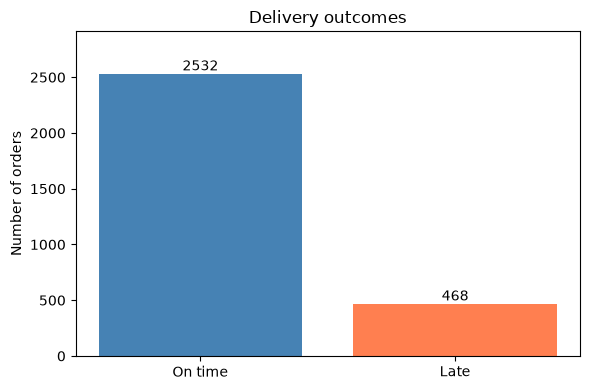

In [9]:
orders = make_orders()

late_rate = orders["late"].mean()
print(f"Total orders: {len(orders):,}")
print(f"Late orders: {orders['late'].sum():,}")
print(f"Late rate: {late_rate:.1%}")

counts = orders["late"].value_counts().reindex([0, 1], fill_value=0)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["On time", "Late"], counts, color=["steelblue", "coral"])
ax.set_title("Delivery outcomes")
ax.set_ylabel("Number of orders")

for position, count in enumerate(counts):
    ax.text(position, count, str(count), ha="center", va="bottom")

ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

## Model comparison

Models were compared using five-fold stratified cross-validation on
the training set only. The table reports the mean and standard
deviation across folds.

Because late orders are uncommon, accuracy alone can be misleading.
The dummy model predicts every order as on time and detects no late orders.

In [10]:
comparison_table = cv_results.set_index("model")

summary_table = pd.DataFrame(index=comparison_table.index)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    summary_table[metric] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(
            comparison_table[f"{metric}_mean"],
            comparison_table[f"{metric}_std"],
            strict=True,
        )
    ]

summary_table

,accuracy,precision,recall,f1,roc_auc
model,,,,,
dummy,0.8440 ± 0.0009,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000
logistic_balanced,0.7387 ± 0.0159,0.3326 ± 0.0266,0.6722 ± 0.0653,0.4448 ± 0.0373,0.7881 ± 0.0368
decision_tree,0.8542 ± 0.0102,0.5957 ± 0.0875,0.2252 ± 0.0548,0.3221 ± 0.0627,0.7432 ± 0.0433
random_forest,0.8582 ± 0.0036,0.6721 ± 0.0335,0.1766 ± 0.0247,0.2792 ± 0.0329,0.7748 ± 0.0356


## Threshold selection

The threshold was selected using out-of-fold predictions on the
training set only.

Each flagged order costs $4. Each missed late order costs $15.
The selected threshold of 0.60 gives the lowest training cost
among the tested thresholds: $4,172.

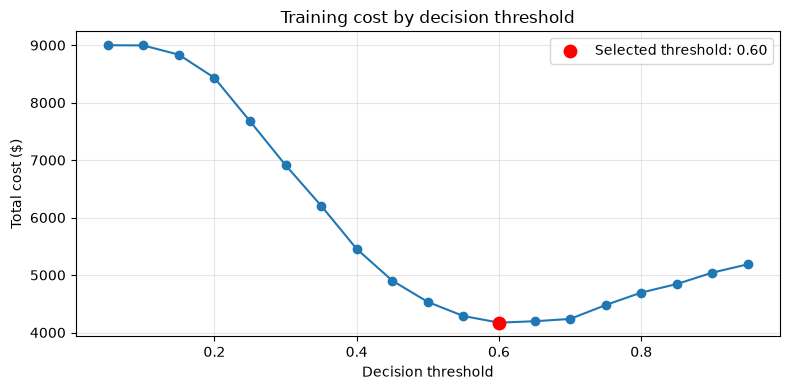

Selected threshold: 0.60
Training cost: $4,172


In [11]:
chosen_threshold = metrics["threshold"]
chosen_row = threshold_costs.loc[
    (threshold_costs["threshold"] - chosen_threshold).abs().idxmin()
]

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    threshold_costs["threshold"],
    threshold_costs["cost"],
    marker="o",
)

ax.scatter(
    chosen_threshold,
    chosen_row["cost"],
    color="red",
    s=80,
    label=f"Selected threshold: {chosen_threshold:.2f}",
    zorder=3,
)

ax.set_title("Training cost by decision threshold")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Total cost ($)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Selected threshold: {chosen_threshold:.2f}")
print(f"Training cost: ${chosen_row['cost']:,.0f}")

## Held-out test results

The model and threshold were fixed before evaluating the 750 test
orders. Rows show actual outcomes; columns show predicted outcomes.

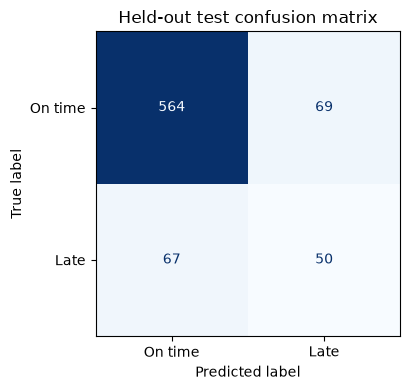

precision    0.4202
recall       0.4274
f1           0.4237
roc_auc      0.7522
Name: Test score, dtype: float64

In [12]:
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 4))

ConfusionMatrixDisplay(
    confusion_matrix=np.array(metrics["confusion_matrix"]),
    display_labels=["On time", "Late"],
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

test_scores = pd.Series(
    {name: metrics[name] for name in ["precision", "recall", "f1", "roc_auc"]},
    name="Test score",
)
test_scores.round(4)

## Policy costs on the test set

We compare the selected model with flagging no orders and flagging
every order. Costs include $4 per flagged order and $15 per missed
late order.

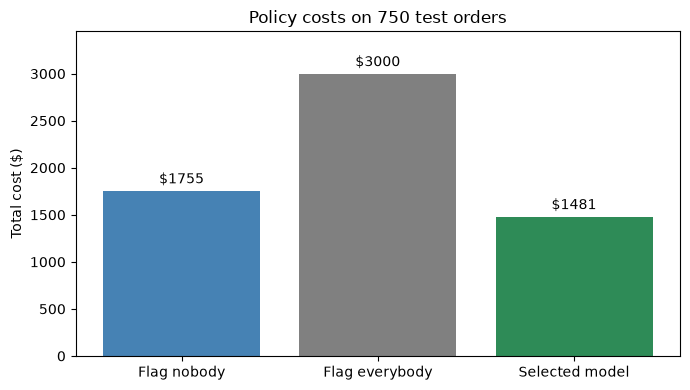

Savings compared with flagging nobody: $274
Percentage saved: 15.6%


In [13]:
policy_costs = pd.Series(
    {
        "Flag nobody": metrics["costs"]["flag_nobody"],
        "Flag everybody": metrics["costs"]["flag_everybody"],
        "Selected model": metrics["costs"]["model"],
    },
    name="Cost ($)",
)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    policy_costs.index,
    policy_costs.values,
    color=["steelblue", "gray", "seagreen"],
)

ax.bar_label(bars, fmt="$%.0f", padding=3)
ax.set_title("Policy costs on 750 test orders")
ax.set_ylabel("Total cost ($)")
ax.set_ylim(0, policy_costs.max() * 1.15)

plt.tight_layout()
plt.show()

savings = policy_costs["Flag nobody"] - policy_costs["Selected model"]
savings_pct = savings / policy_costs["Flag nobody"]

print(f"Savings compared with flagging nobody: ${savings:,}")
print(f"Percentage saved: {savings_pct:.1%}")

## Leakage demonstration

Customer ratings are collected after delivery, so they are unavailable
when an order is placed.

This experiment compares the same logistic model with and without
customer_rating using training-only cross-validation. The extra column
is used only in this experiment; the saved production model is unchanged.

In [14]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

from latedeliveries.pipeline import (
    NUMERIC_FEATURES,
    RANDOM_STATE,
    build_pipeline,
    split_orders,
)

x_train, _, y_train, _ = split_orders(orders)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

clean_pipeline = build_pipeline(
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )
)

clean_scores = cross_val_score(
    clean_pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    error_score="raise",
)

# Add the excluded column only to a separate experimental pipeline.
leaky_features = x_train.copy()
leaky_features["customer_rating"] = orders.loc[x_train.index, "customer_rating"]

leaky_pipeline = clone(clean_pipeline)
preprocessor = leaky_pipeline.named_steps["preprocessor"]

experimental_transformers = [
    (
        name,
        transformer,
        list(columns) + ["customer_rating"]
        if list(columns) == NUMERIC_FEATURES
        else columns,
    )
    for name, transformer, columns in preprocessor.transformers
]

preprocessor.set_params(transformers=experimental_transformers)

leaky_scores = cross_val_score(
    leaky_pipeline,
    leaky_features,
    y_train,
    cv=cv,
    scoring="roc_auc",
    error_score="raise",
)

leakage_comparison = pd.DataFrame(
    {
        "Features": ["Order-time only", "With customer_rating (leakage)"],
        "ROC-AUC mean": [clean_scores.mean(), leaky_scores.mean()],
        "ROC-AUC std": [clean_scores.std(), leaky_scores.std()],
    }
)

print(f"ROC-AUC change from leakage: {leaky_scores.mean() - clean_scores.mean():+.4f}")

leakage_comparison.round(4)

ROC-AUC change from leakage: +0.1219


,Features,ROC-AUC mean,ROC-AUC std
0,Order-time only,0.7881,0.0368
1,With customer_rating (leakage),0.9100,0.0140


## Recommendation

I would consider this model for a monitored pilot, but not immediate
deployment. On 750 synthetic test orders, it costs $1,481 compared with
$1,755 for flagging nobody and $3,000 for flagging everybody. This saves
$274, or 15.6%, against the current policy.

The threshold of 0.60 was chosen by minimizing voucher and missed-late
costs using out-of-fold training predictions. The test set did not
influence this choice.

I excluded order_id because it is an identifier, prep_minutes because
actual preparation time is unknown at order placement, and
customer_rating because it is collected after delivery. The target,
late, is also excluded from the inputs. Vehicle and courier experience
are assumed to be available when the order is placed.

The model still misses 67 of the 117 late test orders. The main
limitation is that the data are synthetic; these savings may not
transfer to real orders. Real-world validation and monitoring are
needed before using the model to issue vouchers.